## ADASYN (Adaptive Synthetic Sampling) 
est une technique de rééquilibrage des classes utilisée pour traiter les datasets déséquilibrés.

Son principe est de générer de nouvelles observations synthétiques pour la classe minoritaire, en accordant davantage d'importance aux observations difficiles à classifier, c'est-à-dire celles dont les voisins sont principalement de la classe majoritaire.

Objectif : améliorer l'apprentissage du modèle en réduisant le déséquilibre entre les classes.

Dans notre cas, ADASYN augmente les observations de la classe 1 (preterm birth) afin de mieux équilibrer les deux classes.

In [16]:
from imblearn.over_sampling import ADASYN
from collections import Counter
import pandas as pd

train = pd.read_csv("train_preprocessed.csv")

X_train = train.drop("preterm_birth", axis=1)
y_train = train["preterm_birth"]

adasyn = ADASYN(
    sampling_strategy='auto',
    n_neighbors=5,
    random_state=42
)

X_train_resampled, y_train_resampled = adasyn.fit_resample(
    X_train, y_train
)

train_resampled = X_train_resampled.copy()
train_resampled["preterm_birth"] = y_train_resampled

In [5]:
train_resampled.to_csv("train_adasyn.csv", index=False)

print("Dataset saved successfully!")

Dataset saved successfully!


In [7]:
print("Before ADASYN:")
print(train["preterm_birth"].value_counts())

print("\nAfter ADASYN:")
print(train_resampled["preterm_birth"].value_counts())

Before ADASYN:
preterm_birth
0    7150
1     850
Name: count, dtype: int64

After ADASYN:
preterm_birth
1    7356
0    7150
Name: count, dtype: int64


In [15]:
print("Percentages before ADASYN:")
print(train["preterm_birth"].value_counts(normalize=True) * 100)

print("\nPercentages after ADASYN:")
print(train_resampled["preterm_birth"].value_counts(normalize=True) * 100)

Percentages before ADASYN:
preterm_birth
0    89.375
1    10.625
Name: proportion, dtype: float64

Percentages after ADASYN:
preterm_birth
1    50.710051
0    49.289949
Name: proportion, dtype: float64


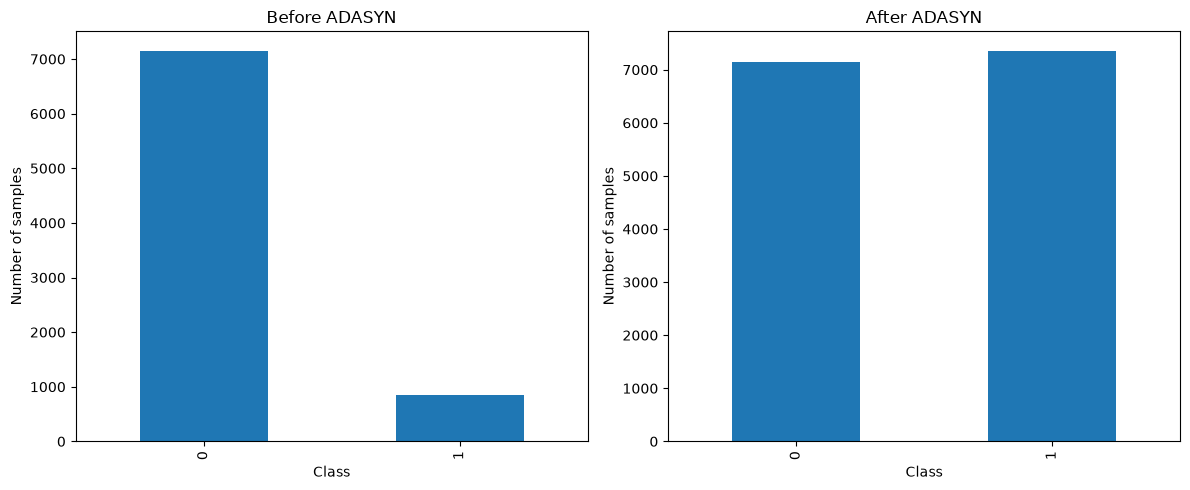

In [11]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

train["preterm_birth"].value_counts().sort_index().plot(
    kind="bar", ax=axes[0], title="Before ADASYN"
)

train_resampled["preterm_birth"].value_counts().sort_index().plot(
    kind="bar", ax=axes[1], title="After ADASYN"
)

axes[0].set_xlabel("Class")
axes[0].set_ylabel("Number of samples")

axes[1].set_xlabel("Class")
axes[1].set_ylabel("Number of samples")

plt.tight_layout()

plt.savefig("adasyn_class_distribution.png", dpi=300, bbox_inches="tight")

plt.show()

## Results and Observations

Before applying ADASYN:

- Class 0: 7,150 samples.

- Class 1: 850 samples.

- Total: 8,000 samples.

After applying ADASYN:

- Class 0: 7,150 samples.

- Class 1: 7,356 samples.

- Total: 14,506 samples.

The class distribution graph shows a significant increase in the number of minority-class samples after applying ADASYN.

## Conclusion

ADASYN successfully reduced the class imbalance by generating 6,506 synthetic samples for class 1.

This preprocessing step can help improve the model's ability to identify preterm birth cases. Model performance should then be evaluated using the original, non-resampled test dataset to ensure a reliable evaluation.